# Vorstudie mit planted effects: MSE vs. SPO+ (lineares Modell, Knapsack)

**Generator** (`make_data("knapsack", "planted", …)` in [prestudy.py](../../src/prestudy.py)): Werte wie in PyEPO $c = 5\,[(Bx/\sqrt p + 3)^{deg} + 1] / 3.5^{deg} \cdot \varepsilon$, aber ohne Aufrunden und mit bewusst gesetztem $B$ und bewusst gesetzten Gewichten. 2-dimensionaler 0-1-Knapsack mit 32 Items, p = 5.

- **Drei Kerngruppen mit je 8 Items** und *denselben* Gewichtsvektoren (wie in PyEPO aus {3,00; …; 7,99}): x1 treibt die erste, x2 die zweite, die dritte hat einen konstanten Wert (Referenz wie die Treppe beim Shortest Path). Bei x = 0 sind alle drei gleich wertvoll. Die Kapazität (ein Drittel des Kerngewichts je Dimension) erzwingt die Auswahl.
- **Ablenker x3 („zu schwer“, 4 Items):** schwerer als die Kapazität, also nie zulässig – für *jedes* Modell entscheidungsirrelevant. SPO+ bekommt für diese Werte keinen Gradienten (vgl. den entscheidungsneutralen Raum beim Shortest Path).
- **Ablenker x4 („gratis“, 4 Items):** Gewicht 0, also bei positivem Wert immer gewählt. Unter den wahren Werten (alle > 0) entscheidungsirrelevant, für ein Modell nur, solange es positive Werte vorhersagt.
- **Rauschfeature** x5 wirkt auf kein Item.

| Gruppe | erwarteter ΔMSE | erwarteter ΔRegret |
|---|---|---|
| kritisch (x1, x2) | groß | groß |
| Ablenker (x3 zu schwer, x4 gratis) | groß | ≈ 0 (Orakel exakt 0) |
| Rauschen (x5) | ≈ 0 | ≈ 0 |

Raster, Training und PFI wie in der Vorstudie ohne planted effects (deg ∈ {1, 2, 4, 6}, noise ∈ {0, 0.5}, n ∈ {100, 1000}, m = 5, K = 10, $n_{test}$ = 1000). Skalenbereinigung nur $s\,\hat c$.

In [1]:
import pandas as pd

import prestudy as v

SIZE = 32
RUN = dict(degs=(1, 2, 4, 6), noises=(0.0, 0.5), ns=(100, 1000), m=5, n_test=1000, K=10, steps=3000)
CSV = v.result_path("knapsack", "planted")
pd.set_option("display.precision", 3)

## 1 Generator prüfen (Sekunden)

Gewichte der Items in beiden Dimensionen (die drei Kerngruppen liegen übereinander, „gratis“ im Ursprung, „zu schwer“ jenseits der Kapazität):

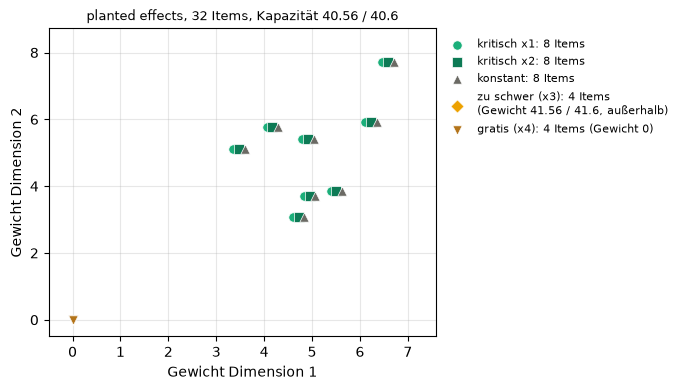

In [2]:
v.plot_structure("knapsack", SIZE)

Anteil gewählter Items je Gruppe unter den wahren Werten (2000 Instanzen). Soll: „zu schwer“ = 0, „gratis“ = 1, die drei Kerngruppen ähnlich oft. Zielbereich laut AP 5: Die häufigste Lösung sollte nicht über ca. 70 % liegen.

In [3]:
pd.DataFrame({(deg, noise): v.decision_shares("knapsack", SIZE, deg, noise)
              for deg in RUN["degs"] for noise in RUN["noises"]}).T.rename_axis(["deg", "noise"])

Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16


kritisch x1  kritisch x2  konstant  zu schwer (x3)  gratis (x4)  \
deg noise                                                                    
1   0.0          0.373        0.374     0.378             0.0          1.0   
    0.5          0.364        0.361     0.361             0.0          1.0   
2   0.0          0.381        0.378     0.352             0.0          1.0   
    0.5          0.358        0.354     0.357             0.0          1.0   
4   0.0          0.386        0.384     0.292             0.0          1.0   
    0.5          0.366        0.359     0.315             0.0          1.0   
6   0.0          0.385        0.385     0.273             0.0          1.0   
    0.5          0.367        0.366     0.291             0.0          1.0   

           Items je Lösung  häufigste Lösung  verschiedene Lösungen  
deg noise                                                            
1   0.0             13.000             0.122                   18.0  
    0.5             12.696             0.003                 1591.0  
2   0.0             12.883             0.098                   21.0  
    0.5             12.554             0.006                 1595.0  
4   0.0             12.498             0.209                   21.0  
    0.5             12.317             0.066                 1300.0  
6   0.0             12.342             0.265                   21.0  
    0.5             12.194             0.134                 1045.0

## 2 Trainingslauf

Lädt die CSV, falls vorhanden; sonst rechnet er ca. 15–20 min (parallel, alle Kerne bis auf zwei). Für eine Neuberechnung die CSV löschen.

In [4]:
if not CSV.exists():
    v.run("knapsack", "planted", SIZE, **RUN).to_csv(CSV, index=False)
df = pd.read_csv(CSV)

Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Academic license - for non-commercial use only - expires 2027-10-16
Set parameter Username
Set parameter LicenseID to value 2875352
Set parameter Username
Set parameter LicenseID to value 2875352
Set parameter Username
Set parameter LicenseID to value 2875352
Academic license - for non-commercial use only - expires 2027-10-16
Academic license - for non-commercial use only - expires 2027-10-16
Academic lic

## 3 Oracle-Check: PFI der wahren Kostenfunktion

Die Rangfolge muss der geplanten entsprechen: ΔRegret nur bei x1, x2 (bei x3, x4, x5 exakt 0); ΔMSE bei x1–x4; x5 = 0.

In [5]:
(df[df.loss == "oracle"]
 .pivot_table(index=["noise", "deg"], columns="feature", values=["d_mse", "d_regret"]))

d_mse                           d_regret                         \
feature       x1     x2     x3     x4   x5       x1     x2   x3         x4   
noise deg                                                                    
0.0   1    0.207  0.209  0.095  0.103  0.0    0.016  0.016  0.0  0.000e+00   
      2    0.612  0.620  0.286  0.303  0.0    0.041  0.041  0.0  0.000e+00   
      4    1.595  1.620  0.763  0.792  0.0    0.098  0.100  0.0  0.000e+00   
      6    2.866  2.936  1.366  1.425  0.0    0.139  0.140  0.0 -1.006e-12   
0.5   1    0.206  0.198  0.096  0.101  0.0    0.015  0.015  0.0  0.000e+00   
      2    0.605  0.602  0.288  0.301  0.0    0.039  0.038  0.0  4.472e-05   
      4    1.568  1.592  0.766  0.786  0.0    0.095  0.095  0.0 -4.666e-06   
      6    2.805  2.898  1.371  1.407  0.0    0.136  0.135  0.0 -5.255e-13   

                
feature     x5  
noise deg       
0.0   1    0.0  
      2    0.0  
      4    0.0  
      6    0.0  
0.5   1    0.0  
      2    0.0  
      4    0.0  
      6    0.0

## 4 Modellgüte

In [6]:
(v.performance(df).query("loss != 'oracle'")
 .groupby(["noise", "n", "deg", "loss"])[["mse", "mse_adj", "regret"]].mean()
 .unstack("loss"))

mse            mse_adj             regret           
loss                    mse    spo+        mse    spo+        mse       spo+
noise n      deg                                                            
0.0   100.0  1    9.288e-05  15.694  2.382e-05  12.922  7.168e-07  3.439e-04
             2    1.002e-02   7.355  1.002e-02   5.738  2.954e-04  5.592e-04
             4    2.047e-01   4.238  2.047e-01   3.462  4.391e-03  8.817e-04
             6    8.880e-01   3.902  8.874e-01   3.810  1.134e-02  1.177e-03
      1000.0 1    6.096e-05  15.188  1.357e-05  11.902  5.385e-07  1.300e-05
             2    9.395e-03   6.722  9.395e-03   4.762  2.868e-04  2.151e-05
             4    1.910e-01   3.751  1.910e-01   3.187  3.995e-03  1.634e-04
             6    8.199e-01   3.940  8.199e-01   3.901  9.774e-03  1.354e-04
0.5   100.0  1    2.912e+00  12.780  2.912e+00   9.355  1.010e-01  1.058e-01
             2    1.605e+00   6.610  1.605e+00   5.180  7.719e-02  8.259e-02
             4    1.211e+00   4.243  1.211e+00   4.046  4.872e-02  4.874e-02
             6    1.821e+00   4.789  1.820e+00   4.759  3.790e-02  3.054e-02
      1000.0 1    2.767e+00  11.300  2.767e+00   7.796  9.502e-02  9.771e-02
             2    1.522e+00   5.722  1.522e+00   4.402  7.389e-02  7.513e-02
             4    1.135e+00   3.700  1.135e+00   3.523  4.691e-02  4.319e-02
             6    1.683e+00   4.292  1.683e+00   4.287  3.553e-02  2.596e-02

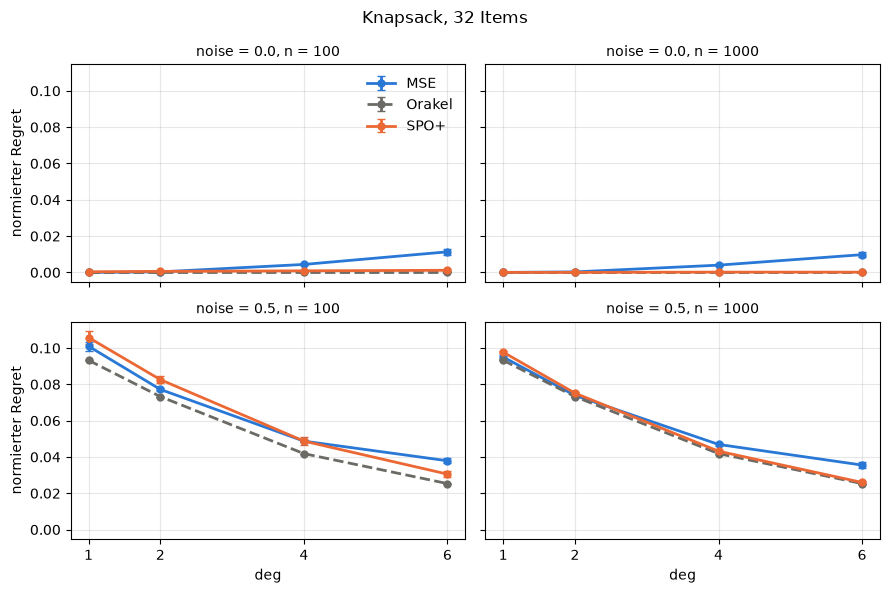

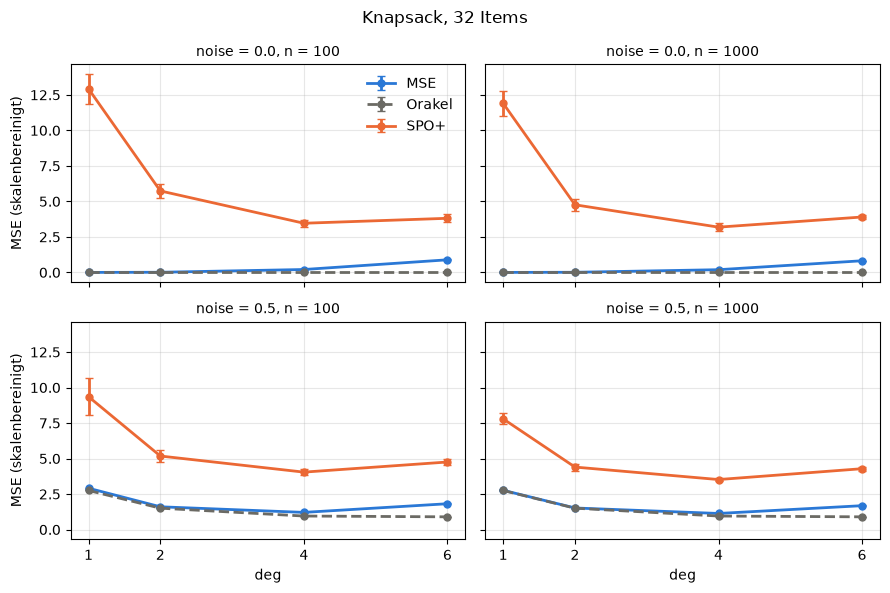

In [7]:
v.plot_over_deg(df, "regret", "normierter Regret", f"Knapsack, {SIZE} Items")
v.plot_over_deg(df, "mse_adj", "MSE (skalenbereinigt)", f"Knapsack, {SIZE} Items")

## 5 PFI je Feature (n = 1000, noise = 0.5)

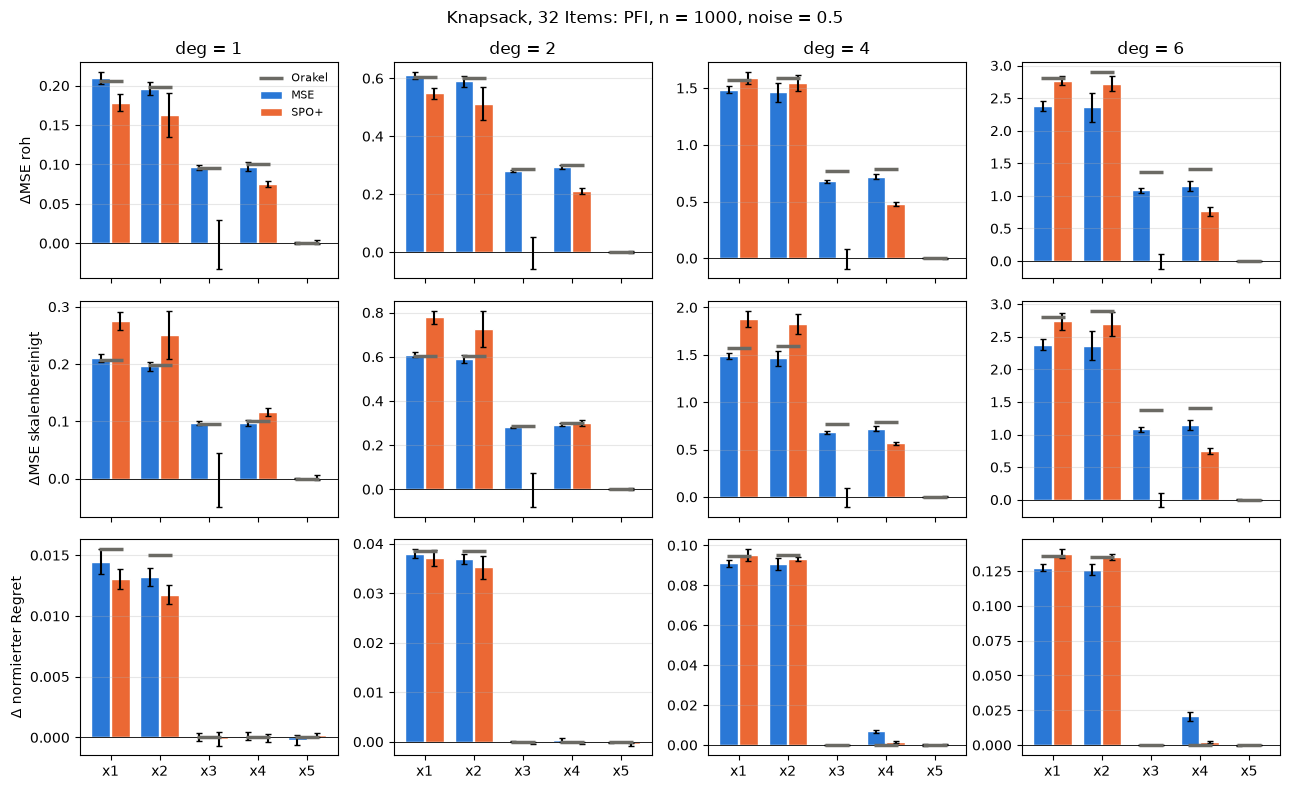

In [8]:
v.plot_pfi(df, title=f"Knapsack, {SIZE} Items:")

## 6 H2: Anteil der Wichtigkeit auf kritischen Features und Ablenkern

Anteil an der Summe der (bei 0 abgeschnittenen) PFI-Werte, je Refit berechnet, dann gemittelt. Die beiden Ablenker-Typen getrennt, weil sie unterschiedlich wirken: „zu schwer“ (x3) ist für jedes Modell irrelevant, „gratis“ (x4) nur bei positiven Vorhersagen. Erwartung: Beim ΔRegret liegt fast alles auf den kritischen Features. Beim ΔMSE hat das MSE-Modell einen großen Anteil auf den Ablenkern, SPO+ einen kleineren.

In [9]:
def share(df, measure, feats):
    vals = df[measure].clip(lower=0)
    keys = ["noise", "n", "deg", "loss", "refit"]
    g = (pd.DataFrame({"part": vals.where(df.feature.isin(feats), 0), "total": vals})
         .groupby([df[c] for c in keys], dropna=False).sum())
    return (g.part / g.total).groupby(level=keys[:-1], dropna=False).mean().unstack("loss")


GROUPS = {"kritisch": ["x1", "x2"], "zu schwer": ["x3"], "gratis": ["x4"]}
h2 = pd.concat({(m, grp): share(df, m, f) for m in ("d_mse_adj", "d_regret") for grp, f in GROUPS.items()}, axis=1)
h2.xs(0.5, level="noise")

d_mse_adj                                                      \
            kritisch               zu schwer               gratis          
loss             mse oracle   spo+       mse oracle   spo+    mse oracle   
n      deg                                                                 
100.0  1       0.670    NaN  0.803     0.154    NaN  0.016  0.174    NaN   
       2       0.672    NaN  0.826     0.156    NaN  0.011  0.171    NaN   
       4       0.672    NaN  0.855     0.158    NaN  0.006  0.170    NaN   
       6       0.670    NaN  0.867     0.160    NaN  0.005  0.170    NaN   
1000.0 1       0.676    NaN  0.799     0.161    NaN  0.019  0.162    NaN   
       2       0.677    NaN  0.822     0.158    NaN  0.011  0.165    NaN   
       4       0.678    NaN  0.862     0.156    NaN  0.007  0.165    NaN   
       6       0.680    NaN  0.873     0.155    NaN  0.005  0.165    NaN   
NaN    1         NaN  0.673    NaN       NaN  0.159    NaN    NaN  0.168   
       2         NaN  0.672    NaN       NaN  0.160    NaN    NaN  0.167   
       4         NaN  0.671    NaN       NaN  0.162    NaN    NaN  0.167   
       6         NaN  0.672    NaN       NaN  0.162    NaN    NaN  0.166   

                  d_regret                                                    \
                  kritisch                zu schwer                   gratis   
loss         spo+      mse oracle   spo+        mse oracle       spo+    mse   
n      deg                                                                     
100.0  1    0.173    0.963    NaN  0.989  3.085e-03    NaN  6.571e-03  0.017   
       2    0.162    0.991    NaN  0.984  3.973e-03    NaN  5.146e-03  0.005   
       4    0.138    0.961    NaN  0.988  1.029e-03    NaN  7.718e-04  0.038   
       6    0.128    0.920    NaN  0.983  2.433e-04    NaN  5.395e-04  0.079   
1000.0 1    0.179    0.988    NaN  0.985  3.392e-03    NaN  3.923e-03  0.006   
       2    0.165    0.994    NaN  1.000  1.284e-03    NaN  2.176e-04  0.004   
       4    0.132    0.963    NaN  0.990  4.062e-04    NaN  4.898e-04  0.037   
       6    0.122    0.924    NaN  0.992  4.039e-04    NaN  3.174e-04  0.076   
NaN    1      NaN      NaN  1.000    NaN        NaN    0.0        NaN    NaN   
       2      NaN      NaN  0.999    NaN        NaN    0.0        NaN    NaN   
       4      NaN      NaN  1.000    NaN        NaN    0.0        NaN    NaN   
       6      NaN      NaN  1.000    NaN        NaN    0.0        NaN    NaN   

                              
                              
loss           oracle   spo+  
n      deg                    
100.0  1          NaN  0.000  
       2          NaN  0.004  
       4          NaN  0.011  
       6          NaN  0.017  
1000.0 1          NaN  0.003  
       2          NaN  0.000  
       4          NaN  0.009  
       6          NaN  0.007  
NaN    1    0.000e+00    NaN  
       2    5.803e-04    NaN  
       4    0.000e+00    NaN  
       6    0.000e+00    NaN

## 7 H1: Rangfolge nach ΔMSE vs. ΔRegret (Kendall's τ)

Nur zur Vergleichbarkeit mit dem Shortest Path; dort hat sich τ als ungeeignet erwiesen (Auswertung, Abschnitt 4).

In [10]:
v.kendall_tau(df)

loss               mse  oracle  spo+
noise n      deg                    
0.0   100.0  1    0.64     NaN  0.56
             2    0.88     NaN  0.72
             4    0.76     NaN  0.88
             6    0.68     NaN  0.96
      1000.0 1    0.63     NaN  0.68
             2    0.72     NaN  0.68
             4    0.80     NaN  0.84
             6    0.76     NaN  0.72
      NaN    1     NaN    0.84   NaN
             2     NaN    0.84   NaN
             4     NaN    0.84   NaN
             6     NaN    0.53   NaN
0.5   100.0  1    0.56     NaN  0.52
             2    0.76     NaN  0.60
             4    0.72     NaN  0.76
             6    0.72     NaN  0.88
      1000.0 1    0.80     NaN  0.64
             2    0.84     NaN  0.76
             4    0.76     NaN  0.84
             6    0.80     NaN  0.92
      NaN    1     NaN    0.84   NaN
             2     NaN    0.95   NaN
             4     NaN    0.53   NaN
             6     NaN    0.32   NaN

## 8 Loss-Effekt je Feature: gepaarte Differenz SPO+ − MSE (n = 1000, noise = 0.5)

`*` = 95-%-Intervall schließt 0 aus (ohne Holm-Korrektur, Pilot).

In [11]:
v.paired_diff(df).unstack("deg").loc[(0.5, 1000)]

d_mse_adj                                          \
deg                       1                   2                   4   
feature                                                               
x1       +0.0654 ± 0.0125 *  +0.1683 ± 0.0229 *  +0.3920 ± 0.0622 *   
x2       +0.0543 ± 0.0349 *  +0.1378 ± 0.0644 *  +0.3655 ± 0.0562 *   
x3       -0.0992 ± 0.0495 *  -0.2839 ± 0.0772 *  -0.6864 ± 0.0955 *   
x4       +0.0192 ± 0.0099 *    +0.0083 ± 0.0177  -0.1543 ± 0.0231 *   
x5         +0.0014 ± 0.0041    +0.0005 ± 0.0040    -0.0003 ± 0.0042   

                                       d_regret                      \
deg                       6                   1                   2   
feature                                                               
x1       +0.3534 ± 0.0756 *  -0.0014 ± 0.0012 *    -0.0009 ± 0.0011   
x2       +0.3295 ± 0.0869 *  -0.0015 ± 0.0010 *  -0.0017 ± 0.0015 *   
x3       -1.0873 ± 0.0909 *    -0.0001 ± 0.0007    -0.0003 ± 0.0003   
x4       -0.3925 ± 0.0349 *    -0.0002 ± 0.0007  -0.0006 ± 0.0002 *   
x5         -0.0026 ± 0.0059    +0.0004 ± 0.0006  -0.0004 ± 0.0003 *   

                                                 
deg                       4                   6  
feature                                          
x1       +0.0041 ± 0.0021 *  +0.0101 ± 0.0014 *  
x2       +0.0026 ± 0.0021 *  +0.0088 ± 0.0021 *  
x3         +0.0001 ± 0.0003    -0.0000 ± 0.0004  
x4       -0.0052 ± 0.0007 *  -0.0188 ± 0.0031 *  
x5         +0.0001 ± 0.0004    +0.0002 ± 0.0004